# Image conversion decorators

- **By:** [Johannes Bereiter-Payr](https://www.johannespayr.eu), 2026  
- **License:** CC-BY 
- **How to cite:** Cite the ORMIR_XCT publication: *Kuczynski et al., (2024). ORMIR_XCT: A Python package for high resolution peripheral quantitative computed tomography image processing. Journal of Open Source Software, 9(97), 6084, https://doi.org/10.21105/joss.06084*

---
# Aims

- This Jupyter Notebook provides an example of how to use decorators to support multiple image representation objects
- Currently supported are conversions between any of `SimpleITK.Image`, `OMidsMedVolume`, `tuple(numpy.ndarray, dict)` and `numpy.ndarray`. Metadata will be preserved as far as possible.
- Decorators also open path strings and `pathlib.Path` objects pointing to supported image files automatically
- Decorators are to be used for all image operation functions included in this library
- For basic information on decorators and the associated syntax see [the python docs](https://docs.python.org/3/glossary.html#term-decorator) or [this extensive primer](https://realpython.com/primer-on-python-decorators/)

  **Table of contents**  
  [1. Imports](#imports)   
  [2. Basic usage](#basic)  
  [3. Advanced options](#advanced)


---

<a name="imports"></a>
## *1. Imports*

Import modules/packages and set the input image path. 

In [1]:
from pathlib import Path

import numpy as np
import SimpleITK as sitk

from ormir_mids.utils import OMidsMedVolume
from ormir_mids.utils.io import load_omids

from ormir_xct.core.util.decorators import request_sitk, request_numpy
from ormir_xct.core.util import file_reader

%matplotlib inline
import matplotlib.pyplot as plt

In [2]:
test_image_path = Path().parent / "images" / "test1.nii"

In [3]:
image = load_omids(str(test_image_path))

---
<a name="basic"></a>
## *2. Basic usage*

Decorators convert arguments passed to a function to an expected type. Consider for example a function which needs to apply an operation specific to a certain type (e.g. `SimpleITK.Image`). By using the `@request_sitk` decorator, you can specify that an image passed to that function will be of the correct type, as long as it is compatible.

For a simple function which only accepts one argument, you can use the decorator without arguments.

In [4]:
@request_sitk
def test_request_sitk_image(input_image):
    # do something specific to SimpleITK images
    print(f"Function received SimpleITK image with size: {input_image.GetSize()}")

You can now pass an image of any supported type to the function, and it will receive a `SimpleITK.Image`:

In [5]:
print(f'Image type passed to function: {type(image)}')
test_request_sitk_image(image)

Image type passed to function: <class 'voxel.med_volume.MedicalVolume'>
Function received SimpleITK image with size: (422, 426, 168)


The decorators also accept strings or `Path` objects, and load the image if possible:

In [6]:
test_request_sitk_image(test_image_path)

Function received SimpleITK image with size: (422, 426, 168)


If the function returns an image, the decorator also converts it back to the original type:

In [7]:
@request_sitk
def test_return_sitk_image(input_image):
    # do something specific to SimpleITK images
    print(f"Function received SimpleITK image with size: {input_image.GetSize()}")
    return input_image

In [8]:
print(f'Image type passed to function: {type(image)}')
returned_image = test_return_sitk_image(image)
print(f'Image type returned by function: {type(returned_image)}')

Image type passed to function: <class 'voxel.med_volume.MedicalVolume'>
Function received SimpleITK image with size: (422, 426, 168)
Image type returned by function: <class 'ormir_mids.utils.OMidsMedVolume.OMidsMedVolume'>


Values which can not be converted to images are passed through:

In [9]:
@request_sitk
def test_return_int(input_image):
    # do something specific to SimpleITK images
    print(f"Function received SimpleITK image with size: {input_image.GetSize()}")
    return 42

In [10]:
print(f'Image type passed to function: {type(image)}')
value = test_return_int(image)
print(f'Function returned {value}')

Image type passed to function: <class 'voxel.med_volume.MedicalVolume'>
Function received SimpleITK image with size: (422, 426, 168)
Function returned 42


If the target function takes more than one parameter, the default behaviour is to expect the first parameter to be the image for conversion.

In [11]:
@request_sitk
def test_multiple_parameters(input_image, other, parameters):
    # do something specific to SimpleITK images
    print(f"Function received SimpleITK image with size: {input_image.GetSize()}")
    print(f"Function received other parameters: {other}, {parameters}")

In [12]:
test_multiple_parameters(image, 42, 'fnord')

Function received SimpleITK image with size: (422, 426, 168)
Function received other parameters: 42, fnord


<a name="basic"></a>
## *3. Advanced options*

For more advanced use cases, the decorator can be parametized. 

If the function return value is of a convertible type, but the type should be preserved, you can pass `convert_result=False` to prevent automatic conversion.

In [13]:
@request_sitk(convert_result=False)
def get_image_slice(image, z):
    # function returns a 2d numpy array
    return np.array(sitk.GetArrayViewFromImage(image)[z, ...], copy=True)

In [14]:
np_slice = get_image_slice(image, 84)
np_slice.shape

(426, 422)

In [15]:
np_slice_b = get_image_slice(image, 42)

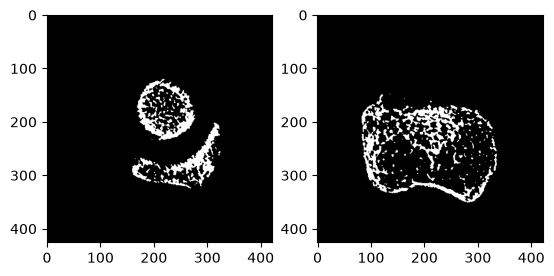

In [16]:
fig, axs = plt.subplots(1, 2)

axs[0].imshow(np_slice, cmap='bone')
axs[1].imshow(np_slice_b, cmap='bone')

If the target function takes more than one image, or the image is not the first parameter, you can pass parameter names to the decorator.

In [17]:
@request_sitk(image_arg_names=('image', 'image_b'))
def test_multi_image(image, image_b):
    filter = sitk.AddImageFilter()
    return filter.Execute(image, image_b)

In [18]:
add_image = test_multi_image(np_slice, np_slice_b)

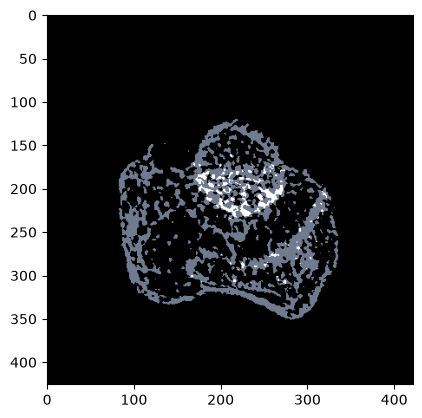

In [19]:
plt.imshow(add_image, cmap='bone')

The decorator can also be configured to reject `None` values for images, to save boilerplate `is not None` checks inside the function. If `accept_none=False`, the decorator will throw a `TypeError` if `None` is passed instead of an image.

In [20]:
@request_numpy(accept_none=False)
def never_none(image):
    print(image.shape)

In [21]:
# None causes a TypeError
try:
    never_none(None)
except TypeError as e:
    print(f"Expected TypeError: {e}")

Expected TypeError: NoneType is not a valid image.


In [22]:
never_none(image)

(422, 426, 168)


---
<a name="attribution"></a>

Notebook created using the [template](https://github.com/ORMIRcommunity/templates/blob/main/ORMIR_nb_template.ipynb) of the [ORMIR community](https://ormircommunity.github.io/) (version 1.0, 2023)